# Evaluación del servicio de IA

> **Aviso de contenido.** El dataset de esta evaluación incluye insultos, amenazas, contenido sexual y spam. Se escribieron a propósito para poder medir la moderación y no reflejan ninguna opinión del autor. Las tablas de errores del notebook los muestran tal cual.

Notebook de evaluación de la puntuación (1–5 estrellas) y la moderación de `ai-service`, con un conjunto de 200 reseñas etiquetadas a mano.

Contenido:
1. Carga y validación del dataset
2. Evaluación de la puntuación
3. Evaluación de la moderación y elección del umbral
4. Conclusiones

## 1. Carga y validación del dataset

In [1]:
from pathlib import Path

import pandas as pd

DATA_PATH = Path("../data/reviews.csv")

El CSV se guardó con BOM y con las columnas alineadas con espacios, así que se lee con `utf-8-sig` y se limpian los espacios sobrantes.

In [2]:
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig", skipinitialspace=True)
df.columns = df.columns.str.strip()
df["text"] = df["text"].str.strip()
df.head()

,id,text,stars,flagged
0,1,Concierto entretenido pero el sonido desde el ...,4.0,0
1,2,!!!!!!!!!!!!!! comprad ya !!!!!!!!!!!!!! ofert...,NaN,1
2,3,"La aplicación es perfecta, rápida, bonita y si...",5.0,0
3,4,ñññññññññññññ estoy probando el comentario ñññ...,NaN,1
4,5,"La cafetera es fantástica, el café sale perfec...",5.0,0


In [3]:
print(f"Filas: {len(df)}")
print(f"Ids únicos: {df['id'].is_unique}")
print(f"Textos duplicados: {df['text'].duplicated().sum()}")
print(f"Textos vacíos: {(df['text'].str.len() == 0).sum()}")
print(f"Longitud mín/máx: {df['text'].str.len().min()} / {df['text'].str.len().max()}")

Filas: 200
Ids únicos: True
Textos duplicados: 0
Textos vacíos: 0
Longitud mín/máx: 47 / 95


Etiquetas válidas: `stars` entre 1 y 5 (o vacía) y `flagged` igual a 0 o 1.

In [4]:
assert df["flagged"].isin([0, 1]).all(), "flagged debe ser 0 o 1 en todas las filas"
assert df["stars"].dropna().isin([1, 2, 3, 4, 5]).all(), "stars debe estar entre 1 y 5"
df["stars"] = df["stars"].astype("Int64")

print("Distribución de flagged:")
print(df["flagged"].value_counts().sort_index().to_string())
print("\nDistribución de stars:")
print(df["stars"].value_counts(dropna=False).sort_index().to_string())

Distribución de flagged:
flagged
0    154
1     46

Distribución de stars:
stars
1       50
2       31
3       14
4       32
5       46
<NA>    27


Cruce entre las dos etiquetas: las reseñas marcadas con `stars` son las que habría que comparar si no se hubieran bloqueado, y las que no tienen `stars` no se pueden puntuar.

In [5]:
pd.crosstab(df["flagged"], df["stars"].isna().map({True: "sin stars", False: "con stars"}))

stars,con stars,sin stars
flagged,,
0,154,0
1,19,27


## 2. Evaluación de la puntuación

Se importa `rate()` directamente de `ai-service`, de modo que se evalúa el código real. El modelo se carga al importar el módulo.

In [6]:
import sys

sys.path.append(str(Path("../../ai-service").resolve()))
from app.rating import rate

IMAGES = Path("../images")
IMAGES.mkdir(exist_ok=True)

C:\Users\samu1\miniconda3\envs\review-ai\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:  15%|█▍        | 30/201 [00:00<00:00, 282.00it/s]

Loading weights:  29%|██▉       | 59/201 [00:00<00:00, 230.09it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 658.17it/s]

Se evalúan todas las reseñas que tienen `stars`, también las que la moderación bloquearía. Así se mide el modelo de estrellas por sí solo; más abajo se repite sin las bloqueadas.

In [7]:
rated = df.dropna(subset=["stars"]).copy()
rated["stars"] = rated["stars"].astype(int)

preds = [rate(text) for text in rated["text"]]
rated["pred"] = [p["stars"] for p in preds]
rated["confidence"] = [p["confidence"] for p in preds]
rated["error"] = rated["pred"] - rated["stars"]
rated["correct"] = rated["error"] == 0
print(f"Reseñas evaluadas: {len(rated)}")

Reseñas evaluadas: 173


### Métricas globales

- **MAE**: error medio en estrellas.
- **Accuracy exacta**: porcentaje en que la predicción coincide con la etiqueta.
- **Accuracy ±1**: porcentaje en que la diferencia es de una estrella como máximo.
- **Sesgo**: error medio con signo; positivo significa que el modelo puntúa por encima de lo etiquetado.

In [8]:
def summary(d):
    return pd.Series({
        "n": len(d),
        "MAE": d["error"].abs().mean(),
        "accuracy exacta": d["correct"].mean(),
        "accuracy ±1": (d["error"].abs() <= 1).mean(),
        "sesgo": d["error"].mean(),
    })

pd.DataFrame({
    "todas": summary(rated),
    "solo no bloqueadas": summary(rated[rated["flagged"] == 0]),
}).round(3)

,todas,solo no bloqueadas
n,173.000,154.000
MAE,0.422,0.390
accuracy exacta,0.636,0.636
accuracy ±1,0.965,0.974
sesgo,-0.179,-0.234


### Matriz de confusión

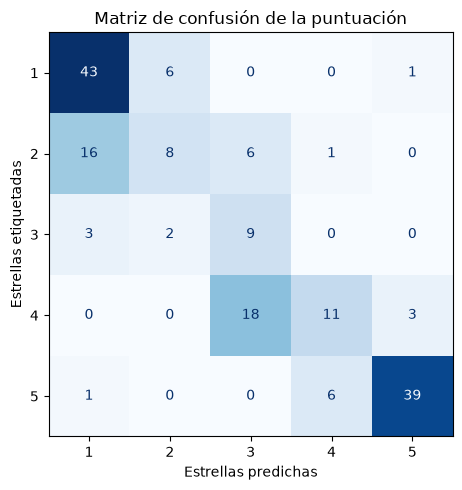

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

labels = [1, 2, 3, 4, 5]
cm = confusion_matrix(rated["stars"], rated["pred"], labels=labels)

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_xlabel("Estrellas predichas")
ax.set_ylabel("Estrellas etiquetadas")
ax.set_title("Matriz de confusión de la puntuación")
fig.tight_layout()
fig.savefig(IMAGES / "rating_confusion_matrix.png", dpi=150)
plt.show()

### Resultados por clase

`support` es el número de reseñas etiquetadas con esa puntuación. En las clases con pocas reseñas, como 3★, las cifras son poco fiables.

In [10]:
from sklearn.metrics import classification_report

report = classification_report(rated["stars"], rated["pred"], labels=labels, output_dict=True, zero_division=0)
pd.DataFrame(report).T.loc[[str(l) for l in labels]].round(3)

,precision,recall,f1-score,support
1,0.683,0.860,0.761,50.0
2,0.500,0.258,0.340,31.0
3,0.273,0.643,0.383,14.0
4,0.611,0.344,0.440,32.0
5,0.907,0.848,0.876,46.0


### ¿Sirve la confianza?

Si `confidence` fuera fiable, las predicciones con más confianza acertarían más. Se agrupan las reseñas por tramos de confianza y se mide la accuracy en cada uno.

In [11]:
rated["tramo"] = pd.cut(rated["confidence"], bins=[0, 0.4, 0.55, 0.7, 0.85, 1.0])
by_conf = rated.groupby("tramo", observed=True).agg(
    n=("correct", "size"),
    accuracy=("correct", "mean"),
    mae=("error", lambda e: e.abs().mean()),
).round(3)
by_conf

,n,accuracy,mae
tramo,,,
"(0.0, 0.4]",9,0.444,0.889
"(0.4, 0.55]",41,0.561,0.537
"(0.55, 0.7]",53,0.547,0.472
"(0.7, 0.85]",34,0.706,0.324
"(0.85, 1.0]",36,0.833,0.194


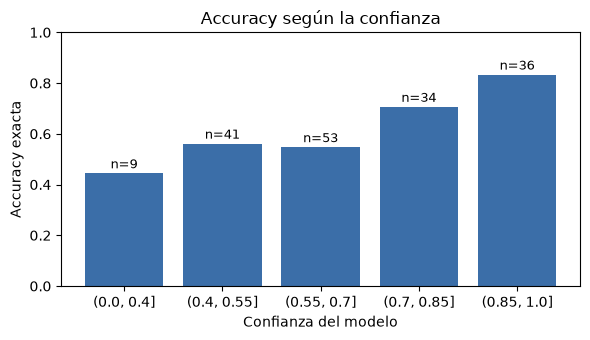

In [12]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(by_conf.index.astype(str), by_conf["accuracy"], color="#3b6ea8")
ax.set_ylim(0, 1)
ax.set_xlabel("Confianza del modelo")
ax.set_ylabel("Accuracy exacta")
ax.set_title("Accuracy según la confianza")
for i, (acc, n) in enumerate(zip(by_conf["accuracy"], by_conf["n"])):
    ax.text(i, acc + 0.02, f"n={n}", ha="center", fontsize=9)
fig.tight_layout()
fig.savefig(IMAGES / "rating_confidence.png", dpi=150)
plt.show()

### Mayores errores

Las reseñas donde la predicción se aleja dos estrellas o más de la etiqueta.

In [13]:
pd.set_option("display.max_colwidth", 90)
worst = rated[rated["error"].abs() >= 2].sort_values("error", key=abs, ascending=False)
print(f"{len(worst)} reseñas con error de 2 o más estrellas")
worst[["id", "text", "stars", "pred", "confidence"]]

6 reseñas con error de 2 o más estrellas


,id,text,stars,pred,confidence
44,45,"Son todos unos ladrones hijos de perra, no vuelvo ni muerto.",1,5,0.46
159,160,Qué rico qué ricooooooooooooo sin palabras ricooooooooooooo,5,1,0.33
40,41,"El local parecía un burdel, gente desnuda y sexo explícito en el salón.",3,1,0.57
75,76,"Instalación complicada y el manual no ayuda nada, aunque una vez puesto funciona.",3,1,0.52
89,90,"La película es puro porno, escenas de sexo explícito sin ningún sentido.",3,1,0.77
188,189,Es una burla que llamen cuatro estrellas a este antro.,2,4,0.89


## 3. Evaluación de la moderación

La moderación combina dos mecanismos: **reglas** (longitud, enlaces, spam) y **Detoxify**, que puntúa siete categorías de toxicidad. Una reseña se marca si salta alguna regla o si alguna categoría de Detoxify alcanza `TOXIC_THRESHOLD`.

Se evalúan las 200 reseñas contra `flagged`, que sigue el criterio del README. Aquí la clase positiva es **marcada** (`flagged = 1`):

- **Precision**: de las reseñas que el sistema marca, cuántas lo merecían. Una precision baja significa bloquear reseñas legítimas.
- **Recall**: de las reseñas que había que marcar, cuántas se marcaron. Un recall bajo significa dejar pasar contenido inadecuado.
- **F1**: media armónica de las dos.

In [14]:
import numpy as np
from app.moderation import CATEGORY_REASONS, TOXIC_THRESHOLD, _check_rules, moderate

categories = list(CATEGORY_REASONS)
print(f"TOXIC_THRESHOLD actual: {TOXIC_THRESHOLD}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 33494.44it/s]

TOXIC_THRESHOLD actual: 0.9


Se ejecuta `moderate()` una sola vez por reseña y se guardan los scores de Detoxify y el resultado de las reglas por separado. Así el barrido de umbrales no necesita volver a pasar el modelo.

In [15]:
mod = df.copy()
results = [moderate(t) for t in mod["text"]]

mod["rule_reasons"] = [_check_rules(t) for t in mod["text"]]
mod["rules_flag"] = mod["rule_reasons"].map(len) > 0
for c in categories:
    mod[c] = [r["scores"][c] for r in results]
mod["max_score"] = mod[categories].max(axis=1)
mod["max_category"] = mod[categories].idxmax(axis=1)
mod["pred_current"] = [r["flagged"] for r in results]

# Comprobación: reglas + Detoxify con el umbral actual reproduce lo que devuelve moderate().
assert (mod["pred_current"] == (mod["rules_flag"] | (mod["max_score"] >= TOXIC_THRESHOLD))).all()

### Sistema actual y cada mecanismo por separado

In [16]:
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score

y = mod["flagged"]

def metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return pd.Series({
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    })

pd.DataFrame({
    "sistema actual": metrics(y, mod["pred_current"]),
    "solo reglas": metrics(y, mod["rules_flag"]),
    "solo Detoxify": metrics(y, mod["max_score"] >= TOXIC_THRESHOLD),
}).T.round(3)

,precision,recall,f1,TP,FP,FN,TN
sistema actual,0.925,0.804,0.86,37.0,3.0,9.0,151.0
solo reglas,1.000,0.370,0.54,17.0,0.0,29.0,154.0
solo Detoxify,0.870,0.435,0.58,20.0,3.0,26.0,151.0


### Dónde se separan las clases

Las reglas ya detectan los enlaces, el spam y las reseñas cortas. Lo que queda por decidir es cómo se reparte el score máximo de Detoxify entre las reseñas que las reglas **no** marcan. Si las dos clases se separan bien en esos scores, habrá un umbral que funcione.

In [17]:
no_rules = mod[~mod["rules_flag"]]
no_rules.groupby("flagged")["max_score"].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
flagged,,,,,,,,
0,154.0,0.068,0.204,0.000,0.001,0.002,0.012,0.946
1,29.0,0.775,0.344,0.002,0.637,0.977,0.994,0.997


### Barrido del umbral

Para cada umbral entre 0.05 y 0.95 se combinan las reglas (que no cambian) con Detoxify y se miden las métricas.

In [18]:
thresholds = np.round(np.arange(0.05, 1.0, 0.05), 2)
sweep = pd.DataFrame({
    thr: metrics(y, mod["rules_flag"] | (mod["max_score"] >= thr)) for thr in thresholds
}).T
sweep.index.name = "umbral"
sweep[["TP", "FP", "FN", "TN"]] = sweep[["TP", "FP", "FN", "TN"]].astype(int)
sweep.round(3)

,precision,recall,f1,TP,FP,FN,TN
umbral,,,,,,,
0.05,0.672,0.935,0.782,43,21,3,133
0.10,0.705,0.935,0.804,43,18,3,136
0.15,0.768,0.935,0.843,43,13,3,141
0.20,0.782,0.935,0.851,43,12,3,142
0.25,0.782,0.935,0.851,43,12,3,142
0.30,0.778,0.913,0.840,42,12,4,142
0.35,0.792,0.913,0.848,42,11,4,143
0.40,0.784,0.870,0.825,40,11,6,143
0.45,0.800,0.870,0.833,40,10,6,144


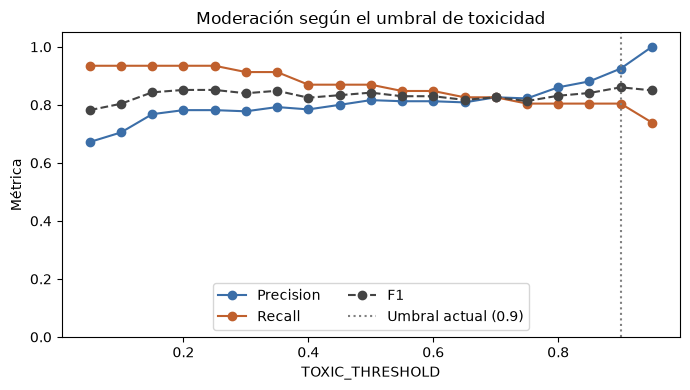

In [19]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sweep.index, sweep["precision"], marker="o", label="Precision", color="#3b6ea8")
ax.plot(sweep.index, sweep["recall"], marker="o", label="Recall", color="#c0602d")
ax.plot(sweep.index, sweep["f1"], marker="o", label="F1", color="#444444", linestyle="--")
ax.axvline(TOXIC_THRESHOLD, color="gray", linestyle=":", label=f"Umbral actual ({TOXIC_THRESHOLD})")
ax.set_xlabel("TOXIC_THRESHOLD")
ax.set_ylabel("Métrica")
ax.set_ylim(0, 1.05)
ax.set_title("Moderación según el umbral de toxicidad")
ax.legend(loc="lower center", ncol=2)
fig.tight_layout()
fig.savefig(IMAGES / "moderation_threshold.png", dpi=150)
plt.show()

### Errores con el umbral actual

**Falsos positivos**: reseñas que no había que marcar y el sistema marcó.

**Falsos negativos**: reseñas que había que marcar y el sistema dejó pasar.

In [20]:
cols = ["id", "text", "rule_reasons", "max_category", "max_score"]
fp = mod[(mod["pred_current"]) & (mod["flagged"] == 0)]
print(f"Falsos positivos: {len(fp)}")
fp[cols]

Falsos positivos: 3


,id,text,rule_reasons,max_category,max_score
70,71,"Maldito el momento en que decidí comprar esto, no funciona nada.",[],obscene,0.904
92,93,"Muy mal todo, patético el nivel de organización del evento.",[],toxicity,0.946
107,108,"Es una porquería de producto, se rompió a la primera semana.",[],toxicity,0.918


In [21]:
fn = mod[(~mod["pred_current"]) & (mod["flagged"] == 1)]
print(f"Falsos negativos: {len(fn)}")
fn[cols]

Falsos negativos: 9


,id,text,rule_reasons,max_category,max_score
11,12,"Las camareras estaban buenísimas, solo pensaba en llevármelas a la cama.",[],toxicity,0.004
15,16,"Más os vale devolverme el dinero o os hago la vida imposible, os lo juro.",[],toxicity,0.364
25,26,Como no me devuelvan el dinero voy a ir con mis amigos y os vamos a destrozar el local.,[],toxicity,0.637
74,75,Si vuelvo a ver a ese camarero le parto la cara.,[],toxicity,0.515
114,115,"Cuidado con lo que haces, sé dónde trabajas y a qué hora sales.",[],toxicity,0.002
124,125,"Te vas a arrepentir, voy a esperarte a la salida y te vas a enterar.",[],toxicity,0.256
174,175,Voy a quemar este sitio con vosotros dentro si no me responden hoy.,[],toxicity,0.728
178,179,"Esos empleados son unos subnormales, no tienen ni idea de nada.",[],toxicity,0.361
199,200,"Os voy a encontrar y vais a pagar por esto, sé dónde vivís.",[],toxicity,0.014


## 4. Conclusiones

### Modelos evaluados

Se evalúan **dos modelos preentrenados, tal como se publican**. No se ha entrenado ni ajustado ninguno con este dataset.

| Tarea | Modelo | Arquitectura y origen |
|---|---|---|
| Puntuación 1–5 | [`nlptown/bert-base-multilingual-uncased-sentiment`](https://huggingface.co/nlptown/bert-base-multilingual-uncased-sentiment) (Hugging Face, `transformers`) | **BERT** multilingüe (`BertForSequenceClassification`, 12 capas, 768 de dimensión oculta, vocabulario de 105 879 tokens), al que se le ha añadido una cabeza de clasificación de 5 clases. Según su ficha, es un `bert-base-multilingual-uncased` ajustado con reseñas de productos en seis idiomas, entre ellos el español. |
| Toxicidad | [Detoxify](https://github.com/unitaryai/detoxify) `multilingual` (checkpoint `multilingual_debiased-0b549669.ckpt`) | **XLM-RoBERTa** (`multilingual_toxic_xlm_r` en el código de la librería), de la familia BERT/RoBERTa y preentrenado en 100 idiomas, entrenado con los datos del Jigsaw Multilingual Toxic Comment. Devuelve siete puntuaciones: `toxicity`, `severe_toxicity`, `obscene`, `identity_attack`, `insult`, `threat` y `sexual_explicit`. |

La moderación completa es **híbrida**: a Detoxify se suman unas **reglas** propias (longitud mínima, enlaces y repeticiones), que no son un modelo. El identificador `model_version` que devuelve el servicio es `nlptown-bert-v1` y se refiere al modelo de estrellas. Versiones de las librerías: `transformers` 5.18.0, `torch` 2.14.1 y `detoxify` 0.5.2.

### Puntuación (173 reseñas con estrellas)

- El modelo acierta la puntuación exacta en el **63.6 %** de los casos y se equivoca como máximo en una estrella en el **96.5 %**. El error medio (MAE) es de **0.42 estrellas**. Los fallos son casi siempre de una estrella.
- Funciona mejor en los extremos: **5★** (F1 0.88) y **1★** (F1 0.76). Es débil en las intermedias, con un recall de 0.26 en **2★** y 0.34 en **4★**: tiende a empujar las opiniones hacia los extremos. 3★ solo tiene 14 reseñas, así que sus cifras son poco fiables.
- Puntúa algo por debajo de lo etiquetado (sesgo de −0.18 estrellas).
- **La confianza es útil**: la accuracy sube del 44 % (confianza ≤ 0.4) al 83 % (confianza > 0.85). Se podría usar para señalar las reseñas dudosas.
- Los 6 errores de dos o más estrellas muestran sus puntos débiles. El modelo se fija en palabras sueltas: *"Es una burla que llamen cuatro estrellas a este antro"* (id 189) recibe 4★ con confianza 0.89. Da 1★ a reseñas que solo describen contenido sexual (ids 41 y 90, etiquetadas 3★), puntúa con 5★ un insulto (id 45, etiquetado 1★), y se equivoca con un texto de sentimiento mixto (id 76) y con letras alargadas (id 160, etiquetado 5★, predicho 1★).

### Moderación (200 reseñas, 46 marcadas)

- Las **reglas** son perfectas en lo que cubren (precision 1.00, ningún falso positivo) pero solo detectan 17 de las 46 reseñas marcadas (recall 0.37). **Detoxify** aporta el resto de la cobertura, y de él vienen todos los errores.
- Se **sube `TOXIC_THRESHOLD` de 0.65 a 0.90**, priorizando que no se bloqueen reseñas legítimas:

| Umbral | Precision | Recall | F1 | Falsos positivos | Falsos negativos |
|---|---|---|---|---|---|
| 0.65 | 0.81 | 0.83 | 0.82 | 9 | 8 |
| **0.90** | **0.93** | **0.80** | **0.86** | **3** | **9** |

- Entre 0.80 y 0.90 el recall no cambia y los falsos positivos bajan de 6 a 3. A 0.95 el recall cae de 37 a 34 aciertos. El umbral queda por tanto en la zona estable, justo antes de la caída.
- **Falsos positivos que quedan (3):** críticas muy duras con vocabulario fuerte, como *"Maldito el momento en que decidí comprar esto"* o *"Es una porquería de producto"*. Detoxify no distingue una crítica contundente de un ataque.
- **Falsos negativos (9):** siete amenazas (*"le parto la cara"*, *"sé dónde trabajas"*), un comentario sexual dirigido a las camareras y un insulto (*"subnormales"*). Detoxify les da scores muy bajos en español, entre 0.002 y 0.73. **No los arregla ningún umbral**: incluso con 0.05 se escapan 3 y se pagan 21 falsos positivos.

### Limitaciones

- Son 200 reseñas **redactadas, cortas** (47 a 95 caracteres) y etiquetadas por **una sola persona**. No hay reseñas reales ni textos largos.
- El umbral se ha elegido con **los mismos datos con los que se mide**, sin un conjunto de prueba aparte, así que las cifras de moderación son optimistas. La diferencia entre 0.85 y 0.90 es de dos reseñas y no es concluyente.
- Las clases intermedias de estrellas (sobre todo 3★) tienen pocos ejemplos.

### Mejoras posibles

- Añadir reglas o patrones para **amenazas** ("te voy a…", "sé dónde…", "te parto…"), que es lo que Detoxify casi no detecta.
- Detectar mensajes que son **solo risas**, que la regla de repetición no cubre.
- Pasar a revisión las puntuaciones con **confianza baja** en lugar de aceptarlas sin más.
- Ampliar el dataset con reseñas reales, un segundo etiquetador y un conjunto de prueba separado del de ajuste.
- Comparar otros modelos de estrellas o de toxicidad; `model_version` permite hacerlo sin cambiar el contrato.